# Predicting anomalous events on Taxi dataset

***Unsupervised anomaly detection on timeseries data a Random Cut Forest algorithm.***

---

1. [Introduction](#Introduction)
1. [Setup](#Setup)
1. [Training](#Training)
1. [Inference](#Inference)

# Introduction
***

Amazon SageMaker Random Cut Forest (RCF) is an algorithm designed to detect anomalous data points within a dataset. Examples of when anomalies are important to detect include when website activity uncharactersitically spikes, when temperature data diverges from a periodic behavior, or when changes to public transit ridership reflect the occurrence of a special event. In this notebook, we will use the SageMaker RCF algorithm to train an RCF model on the Numenta Anomaly Benchmark (NAB) NYC Taxi dataset which records the amount New York City taxi ridership over the course of six months. There are some well know anomalies like NYC marathon, Thanksgiving, Christmas, New Year's day, and on the day of a snow storm. We will then use this model to predict anomalous events by emitting an "anomaly score" for each data point. 

Additional information [SageMaker RCF Documentation](https://docs.aws.amazon.com/sagemaker/latest/dg/randomcutforest.html).

In [1]:
import boto3
import botocore
import sagemaker
import sys

execution_role = sagemaker.get_execution_role()

bucket = 'alexbc.datalake'
prefix = 'machine-learning-models/sagemaker/rcf-benchmarks'
boto3.Session().client('s3').head_bucket(Bucket=bucket)
    
print('Training input/output will be stored in: s3://{}/{}'.format(bucket, prefix))

Training input/output will be stored in: s3://alexbc.datalake/machine-learning-models/sagemaker/rcf-benchmarks


In [3]:
%%time

import pandas as pd
import urllib.request

data_filename = 'passengers_by_halfhour.csv'
data_source = 'https://s3.amazonaws.com/alexbc.datalake/ny-taxi-data/taxi_datamart/' + data_filename
urllib.request.urlretrieve(data_source, data_filename)
taxi_data = pd.read_csv(data_filename, delimiter=',')

CPU times: user 12 ms, sys: 12 ms, total: 24 ms
Wall time: 87.5 ms


Before training any models it is important to inspect our data, first. Perhaps there are some underlying patterns or structures that we could provide as "hints" to the model or maybe there is some noise that we could pre-process away. The raw data looks like this:

In [4]:
taxi_data.head()

,timestamp,value
0,2014-07-01 00:00:00,10844
1,2014-07-01 00:30:00,8127
2,2014-07-01 01:00:00,6210
3,2014-07-01 01:30:00,4656
4,2014-07-01 02:00:00,3820


Human beings are visual creatures so let's take a look at a plot of the data.

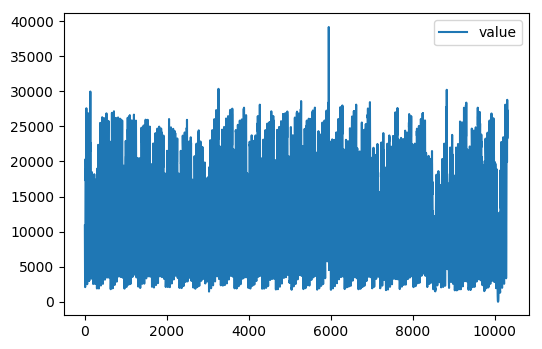

In [5]:
%matplotlib inline

import matplotlib
import matplotlib.pyplot as plt
matplotlib.rcParams['figure.dpi'] = 100

taxi_data.plot()

Human beings are also extraordinarily good at perceiving patterns. Note, for example, that something uncharacteristic occurs at around datapoint number 6000. Additionally, as we might expect with taxi ridership, the passenger count appears more or less periodic. Let's zoom in to not only examine this anomaly but also to get a better picture of what the "normal" data looks like.

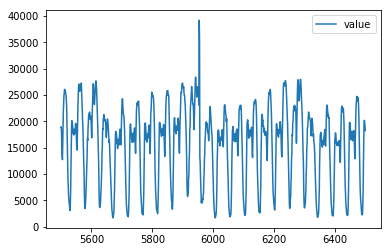

In [5]:
taxi_data[5500:6500].plot()

Here we see that the number of taxi trips taken is mostly periodic with one mode of length approximately 50 data points. In fact, the mode is length 48 since each datapoint represents a 30-minute bin of ridership count. Therefore, we expect another mode of length $336 = 48 \times 7$, the length of a week. Smaller frequencies over the course of the day occur, as well.

For example, here is the data across the day containing the above anomaly:

In [6]:
taxi_data[5952:6003]

,timestamp,value
5952,2014-11-02 00:00:00,25110
5953,2014-11-02 00:30:00,23109
5954,2014-11-02 01:00:00,39197
5955,2014-11-02 01:30:00,35212
5956,2014-11-02 02:00:00,13259
5957,2014-11-02 02:30:00,12250
5958,2014-11-02 03:00:00,10013
5959,2014-11-02 03:30:00,7898
5960,2014-11-02 04:00:00,6375
5961,2014-11-02 04:30:00,4532


## Data preparation storing data on S3

The Random Cut Forest Algorithm accepts data in [RecordIO](https://mxnet.apache.org/api/python/io/io.html#module-mxnet.recordio) [Protobuf](https://developers.google.com/protocol-buffers/) format. The SageMaker Python API provides helper functions for easily converting your data into this format. Below we convert the taxicab data and upload it to the `bucket + prefix` Amazon S3 destination specified at the beginning of this notebook in the [Setup AWS Credentials](#Setup-AWS-Credentials) section.

In [6]:
def convert_and_upload_training_data(ndarray, bucket, prefix, filename='data.pbr'):
    #import boto3
    import os
    from sagemaker.amazon.common import numpy_to_record_serializer
    
    # convert numpy array to Protobuf RecordIO format
    serializer = numpy_to_record_serializer()
    buffer = serializer(ndarray)
    
    # Upload to S3
    s3_object = os.path.join(prefix, 'train', filename)
    boto3.Session().resource('s3').Bucket(bucket).Object(s3_object).upload_fileobj(buffer)
    
    s3_path = 's3://{}/{}'.format(bucket, s3_object)
    return s3_path


# RCV only works on an array of values.
s3_train_data = convert_and_upload_training_data(
    taxi_data.value.as_matrix().reshape(-1,1),
    bucket,
    prefix)
print('Uploaded data to {}'.format(s3_train_data))

Uploaded data to s3://alexbc.datalake/machine-learning-models/sagemaker/rcf-benchmarks/train/data.pbr


# Training

***

We have created a training data set and uploaded it to S3. Next, we configure a SageMaker training job to use the Random Cut Forest (RCF) algorithm on said training data.

The first step is to specify the location of the Docker image containing the SageMaker Random Cut Forest algorithm. In order to minimize communication latency, we provide containers for each AWS region in which SageMaker is available.

## Hyperparameters

Particular to a SageMaker RCF training job are the following hyperparameters:

* **`num_samples_per_tree`** - the number randomly sampled data points sent to each tree. As a general rule, `1/num_samples_per_tree` should approximate the the estimated ratio of anomalies to normal points in the dataset.
* **`num_trees`** - the number of trees to create in the forest. Each tree learns a separate model from different samples of data. The full forest model uses the mean predicted anomaly score from each constituent tree.
* **`feature_dim`** - the dimension of each data point.

In addition to these RCF model hyperparameters, we provide additional parameters defining things like the EC2 instance type on which training will run, the S3 bucket containing the data, and the AWS access role. Note that,

* Recommended instance type: `ml.m4`, `ml.c4`, or `ml.c5`
* Current limitations:
  * The RCF algorithm does not take advantage of GPU hardware.

In [7]:
session = sagemaker.Session()

container = "382416733822.dkr.ecr.us-east-1.amazonaws.com/randomcutforest:latest"

# specify general training job information
rcf = sagemaker.estimator.Estimator(
    container,
    execution_role,
    output_path='s3://{}/{}/output'.format(bucket, prefix),
    train_instance_count=1,
    train_instance_type='ml.m4.xlarge',
    sagemaker_session=session,
)

# set algorithm-specific hyperparameters
rcf.set_hyperparameters(
    num_samples_per_tree = 200,
    num_trees = 50,
    feature_dim = 1,
)

# RCF training requires sharded data. See documentation for
# more information.
s3_train_input = sagemaker.session.s3_input(
    s3_train_data,
    distribution='ShardedByS3Key',
    content_type='application/x-recordio-protobuf',
)

# run the training job on input data stored in S3
rcf.fit({'train': s3_train_input})

INFO:sagemaker:Creating training-job with name: randomcutforest-2018-09-19-02-23-11-567


.......................
Docker entrypoint called with argument(s): train
[09/19/2018 02:26:49 INFO 140669578307392] Reading default configuration from /opt/amazon/lib/python2.7/site-packages/algorithm/resources/default-conf.json: {u'_ftp_port': 8999, u'num_samples_per_tree': 256, u'_tuning_objective_metric': u'', u'_num_gpus': u'auto', u'_log_level': u'info', u'_kvstore': u'dist_async', u'force_dense': u'true', u'epochs': 1, u'num_trees': 100, u'eval_metrics': [u'accuracy', u'precision_recall_fscore'], u'_num_kv_servers': u'auto', u'mini_batch_size': 1000}
[09/19/2018 02:26:49 INFO 140669578307392] Reading provided configuration from /opt/ml/input/config/hyperparameters.json: {u'feature_dim': u'1', u'num_samples_per_tree': u'200', u'num_trees': u'50'}
[09/19/2018 02:26:49 INFO 140669578307392] Final configuration: {u'_ftp_port': 8999, u'num_samples_per_tree': u'200', u'_tuning_objective_metric': u'', u'_num_gpus': u'auto', u'_log_level': u'info', u'_kvstore': u'dist_async', u'force_den


Billable seconds: 124


at the bottom of the output logs then that means training successfully completed and the output RCF model was stored in the specified output path. You can also view information about and the status of a training job using the AWS SageMaker console. Just click on the "Jobs" tab and select training job matching the training job name, below:

In [9]:
print('Training job name: {}'.format(rcf.latest_training_job.job_name))

Training job name: randomcutforest-2018-09-16-13-51-20-328


# Inference

***

A trained Random Cut Forest model does nothing on its own. We now want to use the model we computed to perform inference on data. In this case, it means computing anomaly scores from input time series data points.

We create an inference endpoint using the SageMaker Python SDK `deploy()` function from the job we defined above. We specify the instance type where inference is computed as well as an initial number of instances to spin up. We recommend using the `ml.c5` instance type as it provides the fastest inference time at the lowest cost.

In [10]:
rcf_inference = rcf.deploy(
    initial_instance_count=1,
    instance_type='ml.m4.xlarge',
)

INFO:sagemaker:Creating model with name: randomcutforest-2018-09-16-14-22-26-231
INFO:sagemaker:Creating endpoint with name randomcutforest-2018-09-16-13-51-20-328


---------------------------------------------------------------!

In [11]:
print('Endpoint name: {}'.format(rcf_inference.endpoint))

Endpoint name: randomcutforest-2018-09-16-13-51-20-328


## Data Serialization/Deserialization

We can pass data in a variety of formats to our inference endpoint. In this example we will demonstrate passing CSV-formatted data. Other available formats are JSON-formatted and RecordIO Protobuf. We make use of the SageMaker Python SDK utilities `csv_serializer` and `json_deserializer` when configuring the inference endpoint.

In [18]:
from sagemaker.predictor import csv_serializer, json_deserializer

rcf_inference.content_type = 'text/csv'
rcf_inference.serializer = csv_serializer
rcf_inference.deserializer = json_deserializer

Let's pass the training dataset, in CSV format, to the inference endpoint so we can automatically detect the anomalies we saw with our eyes in the plots, above. Note that the serializer and deserializer will automatically take care of the datatype conversion from Numpy NDArrays.

For starters, let's only pass in the first six datapoints so we can see what the output looks like.

In [19]:
taxi_data_numpy = taxi_data.value.as_matrix().reshape(-1,1)
results = rcf_inference.predict(taxi_data_numpy[:6])

#print(taxi_data[:6])
print(results)

{'scores': [{'score': 0.9629906126}, {'score': 0.9128930667}, {'score': 0.9788263749}, {'score': 0.8434075936}, {'score': 0.9370753111}, {'score': 0.8481088544}]}


## Computing Anomaly Scores

Now, let's compute and plot the anomaly scores from the entire taxi dataset.

In [20]:
results = rcf_inference.predict(taxi_data_numpy)
scores = [datum['score'] for datum in results['scores']]

# add scores to taxi data frame and print first few values
taxi_data['score'] = pd.Series(scores, index=taxi_data.index)
taxi_data.head()

,timestamp,value,score
0,2014-07-01 00:00:00,10844,0.962991
1,2014-07-01 00:30:00,8127,0.912893
2,2014-07-01 01:00:00,6210,0.978826
3,2014-07-01 01:30:00,4656,0.843408
4,2014-07-01 02:00:00,3820,0.937075


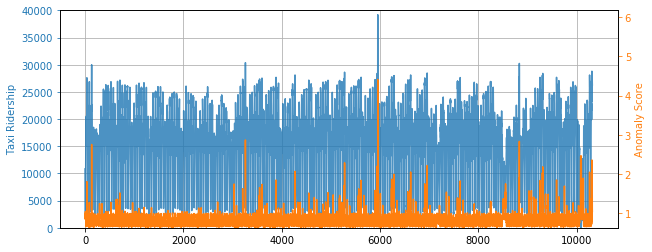

In [21]:
fig, ax1 = plt.subplots()
ax2 = ax1.twinx()

#
# *Try this out* - change `start` and `end` to zoom in on the 
# anomaly found earlier in this notebook
#
start, end = 0, len(taxi_data)
#start, end = 5500, 6500
taxi_data_subset = taxi_data[start:end]

ax1.plot(taxi_data_subset['value'], color='C0', alpha=0.8)
ax2.plot(taxi_data_subset['score'], color='C1')

ax1.grid(which='major', axis='both')

ax1.set_ylabel('Taxi Ridership', color='C0')
ax2.set_ylabel('Anomaly Score', color='C1')

ax1.tick_params('y', colors='C0')
ax2.tick_params('y', colors='C1')

ax1.set_ylim(0, 40000)
ax2.set_ylim(min(scores), 1.4*max(scores))
fig.set_figwidth(10)

Note that the anomaly score spikes where our eyeball-norm method suggests there is an anomalous data point as well as in some places where our eyeballs are not as accurate.

Below we print and plot any data points with scores greater than 3 standard deviations (approx 99.9th percentile) from the mean score.

In [16]:
score_mean = taxi_data['score'].mean()
score_std = taxi_data['score'].std()
score_cutoff = score_mean + 3*score_std

anomalies = taxi_data_subset[taxi_data_subset['score'] > score_cutoff]
anomalies

,timestamp,value,score
37,2014-07-01 18:30:00,27598,1.803230
134,2014-07-03 19:00:00,29985,2.750798
661,2014-07-14 18:30:00,26945,1.354454
710,2014-07-15 19:00:00,27167,1.515914
3031,2014-09-02 03:30:00,1431,1.744335
3032,2014-09-02 04:00:00,1752,1.371922
3206,2014-09-05 19:00:00,27337,1.624773
3261,2014-09-06 22:30:00,30313,2.866019
3262,2014-09-06 23:00:00,30373,2.865733
3263,2014-09-06 23:30:00,28464,2.204600


The following is a list of known anomalous events which occurred in New York City within this timeframe:

* `2014-11-02` - NYC Marathon
* `2015-01-01` - New Year's Eve
* `2015-01-27` - Snowstorm

Note that our algorithm managed to capture these events along with quite a few others. Below we add these anomalies to the score plot.

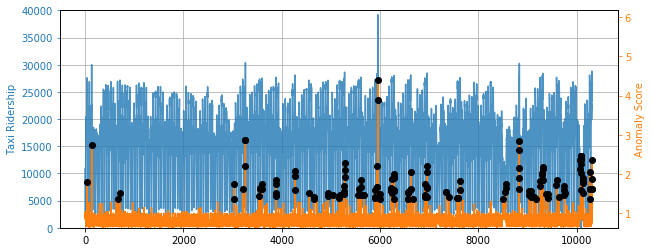

In [17]:
ax2.plot(anomalies.index, anomalies.score, 'ko')
fig

With the current hyperparameter choices we see that the three-standard-deviation threshold, while able to capture the known anomalies as well as the ones apparent in the ridership plot, is rather sensitive to fine-grained peruturbations and anomalous behavior. Adding trees to the SageMaker RCF model could smooth out the results as well as using a larger data set.

## Stop and Delete the Endpoint

In [22]:
sagemaker.Session().delete_endpoint(rcf_inference.endpoint)

INFO:sagemaker:Deleting endpoint with name: randomcutforest-2018-09-16-13-51-20-328
